# Clasificación de tumores de mama con regresión logística

**Objetivo:** predecir si un tumor es maligno o benigno a partir de medidas morfológicas obtenidas de imágenes de biopsias, priorizando el *recall* de la clase maligna (es decir, minimizar los falsos negativos).

**Resultado:** el mejor de los tres pipelines comparados alcanza **recall 0.952**, **precisión 1.000**, **exactitud 0.982** y **AUC 0.992** en el conjunto de prueba.

**Autor:** Alan Castro · Proyecto académico en equipo (4 integrantes)

---

## Datos

Se usa el conjunto *Breast Cancer Wisconsin (Diagnostic)*, disponible en el repositorio UCI Machine Learning: 569 tumores descritos por 30 variables numéricas y una etiqueta de diagnóstico.

Cada característica se presenta en tres medidas:

* `_mean`: valor promedio de la característica en el tumor
* `_se`: error estándar de la característica (variabilidad de la medición)
* `_worst`: peor valor observado de la característica en el tumor

| Característica | Descripción |
|---|---|
| `radius` | Radio del tumor |
| `texture` | Textura (desviación estándar de la intensidad) |
| `perimeter` | Perímetro del tumor |
| `area` | Área del tumor |
| `smoothness` | Suavidad (irregularidad del borde) |
| `compactness` | Compacidad (perímetro² / área − 1) |
| `concavity` | Concavidad de los contornos |
| `concave points` | Número de puntos cóncavos en el contorno |
| `symmetry` | Simetría del tumor |
| `fractal_dimension` | Dimensión fractal del contorno (complejidad) |

La variable objetivo es `diagnosis`: benigno (`B`) o maligno (`M`).

In [1]:
# Importar las bibliotecas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PowerTransformer
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, roc_auc_score

## 1. Carga y exploración inicial

Se cargan los datos con `id` como índice y se revisan tipos de datos, valores faltantes, registros duplicados y estadísticas descriptivas (con asimetría y curtosis para las variables numéricas).

In [2]:
cancer_df = pd.read_csv('data/breast_cancer.csv').set_index('id')

cancer_df.info()

n_numericas = cancer_df.select_dtypes(include='number').shape[1]
n_texto = cancer_df.shape[1] - n_numericas
print(f"\nColumnas numéricas: {n_numericas} | Columnas de texto: {n_texto}")

print("Valores faltantes (total):", cancer_df.isnull().sum().sum())

print("Registros duplicados:", cancer_df.duplicated().sum())
if cancer_df.duplicated().sum() > 0:
    cancer_df = cancer_df.drop_duplicates().reset_index(drop=True)

desc_num = cancer_df.describe().T
desc_num['skew'] = cancer_df.select_dtypes(include='number').skew()
desc_num['kurtosis'] = cancer_df.select_dtypes(include='number').kurt()
display(desc_num.round(3))

display(cancer_df.describe(include='object'))

<class 'pandas.core.frame.DataFrame'>
Index: 569 entries, 842302 to 92751
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                 

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
radius_mean,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110,0.942,0.846
texture_mean,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280,0.650,0.758
perimeter_mean,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500,0.991,0.972
area_mean,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000,1.646,3.652
smoothness_mean,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163,0.456,0.856
compactness_mean,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345,1.190,1.650
concavity_mean,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427,1.401,1.999
concave points_mean,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201,1.171,1.067
symmetry_mean,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304,0.726,1.288
fractal_dimension_mean,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097,1.304,3.006


,diagnosis
count,569
unique,2
top,B
freq,357


> **Tipos de datos:** el conjunto tiene **30 columnas numéricas** (`float64`) y **1 columna de texto** (`diagnosis`, de tipo `object`), que corresponde a la variable objetivo.
>
> **Calidad de los datos:** no se detectaron **valores faltantes** ni **registros duplicados**, por lo que el índice `id` se conserva sin necesidad de reiniciarlo.

## 2. Análisis bivariado

Se explora la distribución de la variable objetivo y cómo se relacionan las variables físicas y morfológicas con el diagnóstico.

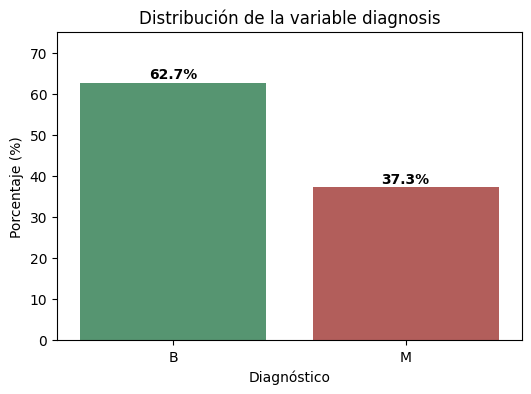

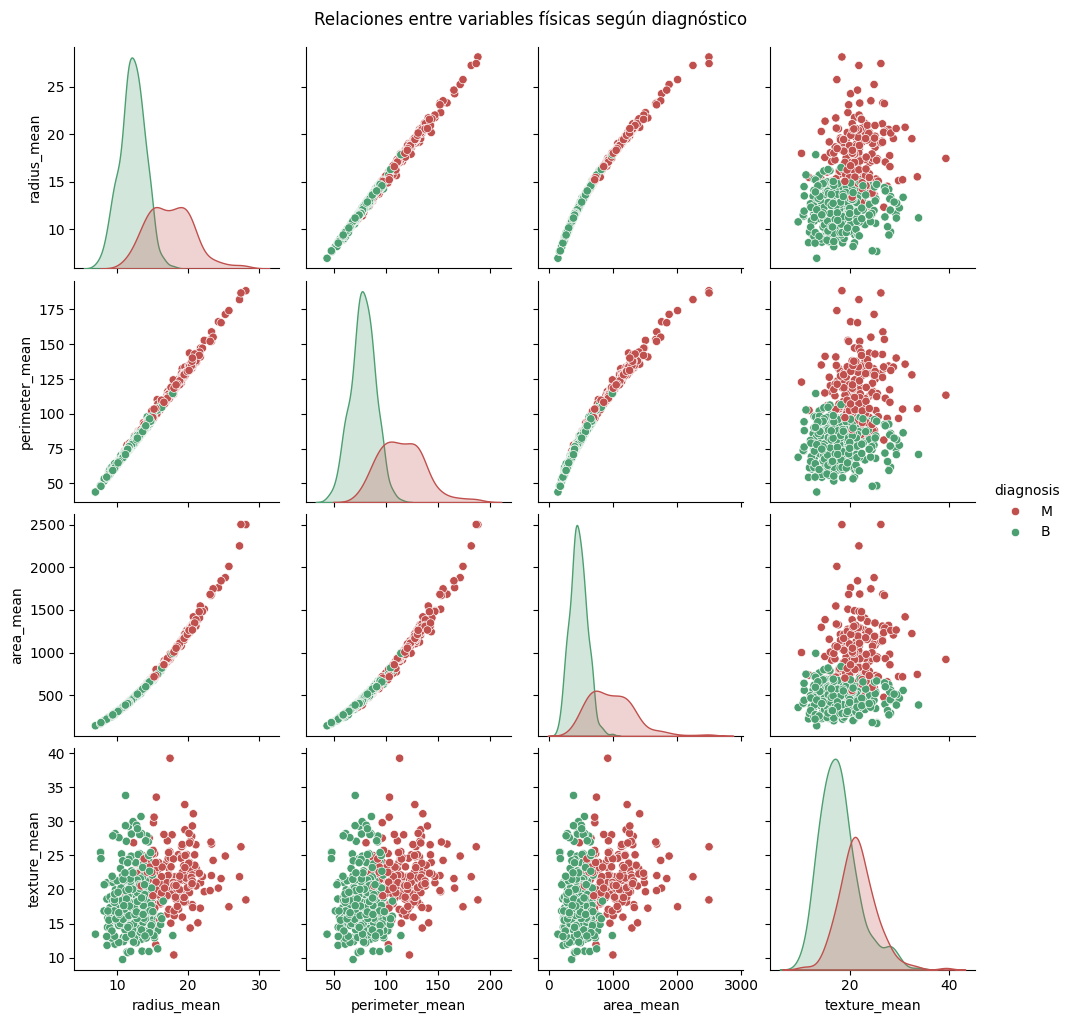

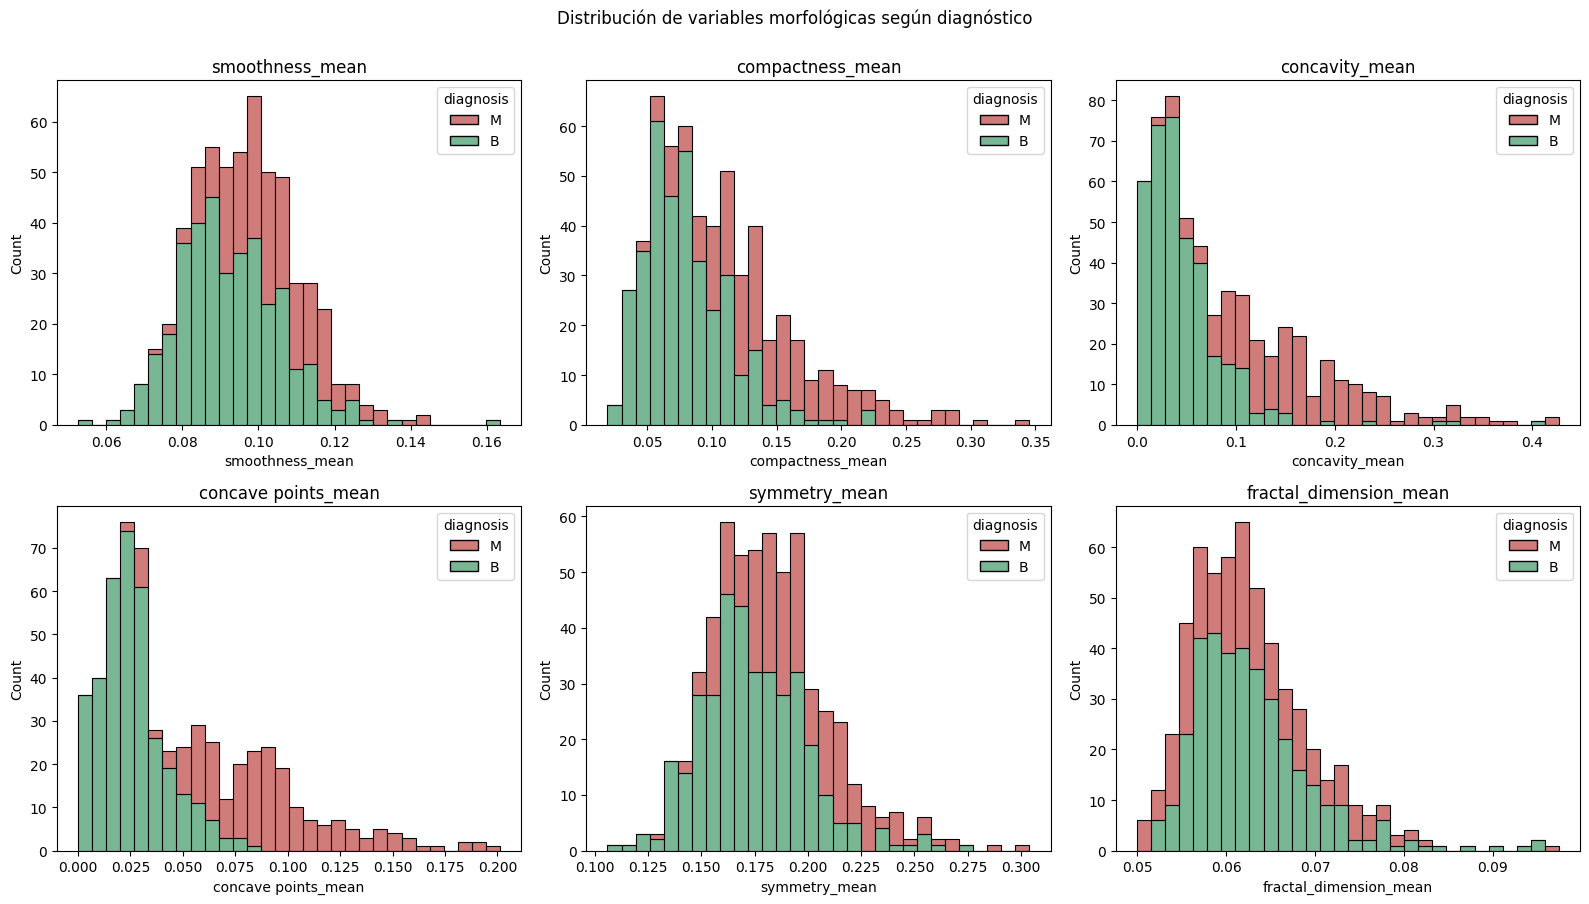

In [3]:
dist = cancer_df['diagnosis'].value_counts(normalize=True).mul(100).reindex(['B', 'M'])

plt.figure(figsize=(6, 4))
ax = sns.barplot(x=dist.index, y=dist.values, hue=dist.index,
                 palette={'B': '#4C9F70', 'M': '#C0504D'}, legend=False)
for i, v in enumerate(dist.values):
    ax.text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')
ax.set(xlabel='Diagnóstico', ylabel='Porcentaje (%)', ylim=(0, 75),
       title='Distribución de la variable diagnosis')
plt.show()

fisicas = ['radius_mean', 'perimeter_mean', 'area_mean', 'texture_mean']
sns.pairplot(cancer_df[fisicas + ['diagnosis']], hue='diagnosis',
             palette={'B': '#4C9F70', 'M': '#C0504D'}, diag_kind='kde')
plt.suptitle('Relaciones entre variables físicas según diagnóstico', y=1.02)
plt.show()

morfologicas = ['smoothness_mean', 'compactness_mean', 'concavity_mean',
                'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for var, ax in zip(morfologicas, axes.ravel()):
    sns.histplot(data=cancer_df, x=var, hue='diagnosis', multiple='stack',
                 palette={'B': '#4C9F70', 'M': '#C0504D'}, bins=30, ax=ax)
    ax.set_title(var)
fig.suptitle('Distribución de variables morfológicas según diagnóstico', y=1.0)
plt.tight_layout()
plt.show()

**¿Por qué la distribución de la salida es relevante en un problema de clasificación?**

La proporción de clases condiciona tanto el aprendizaje como la evaluación del modelo. Aquí existe un desbalance moderado (**62.7 % benignos** frente a **37.3 % malignos**): no es extremo, pero sí suficiente para que la *exactitud* por sí sola pueda resultar engañosa (un clasificador que prediga siempre "benigno" acertaría cerca del 63 %). Por eso conviene apoyarse también en métricas como el *recall* y la *precisión*.

**¿Qué relaciones observas entre las variables físicas? ¿Qué diferencias hay entre benignos y malignos?**

`radius_mean`, `perimeter_mean` y `area_mean` muestran relaciones casi perfectamente lineales entre sí (son medidas geométricamente dependientes), mientras que `texture_mean` es más independiente. Los tumores **malignos** se ubican de forma consistente en valores **más altos** de tamaño y se separan bastante bien de los benignos, aunque con cierto solapamiento.

**¿Alguna variable parece ser un buen discriminador entre las clases?**

Sí. `concave points_mean` y `concavity_mean` son las que mejor separan las clases: los benignos se concentran en valores bajos y los malignos se extienden hacia valores altos. `compactness_mean` también discrimina de forma aceptable, mientras que `smoothness_mean`, `symmetry_mean` y `fractal_dimension_mean` presentan mayor solapamiento.

## 3. Correlación y reducción de redundancia

Sobre una copia del dataframe se identifican los pares de variables con correlación superior a 0.9 y se descartan las redundantes en tres pasos: las columnas `_worst`, las medidas de `perimeter` y `area`, y finalmente `concavity_mean`.

Pares con correlación > 0.9 (conjunto completo):
radius_mean          perimeter_mean          0.998
radius_worst         perimeter_worst         0.994
radius_mean          area_mean               0.987
perimeter_mean       area_mean               0.987
radius_worst         area_worst              0.984
perimeter_worst      area_worst              0.978
radius_se            perimeter_se            0.973
perimeter_mean       perimeter_worst         0.970
radius_mean          radius_worst            0.970
perimeter_mean       radius_worst            0.969
radius_mean          perimeter_worst         0.965
area_mean            radius_worst            0.963
                     area_worst              0.959
                     perimeter_worst         0.959
radius_se            area_se                 0.952
perimeter_mean       area_worst              0.942
radius_mean          area_worst              0.941
perimeter_se         area_se                 0.938
concavity_mean       concave poin

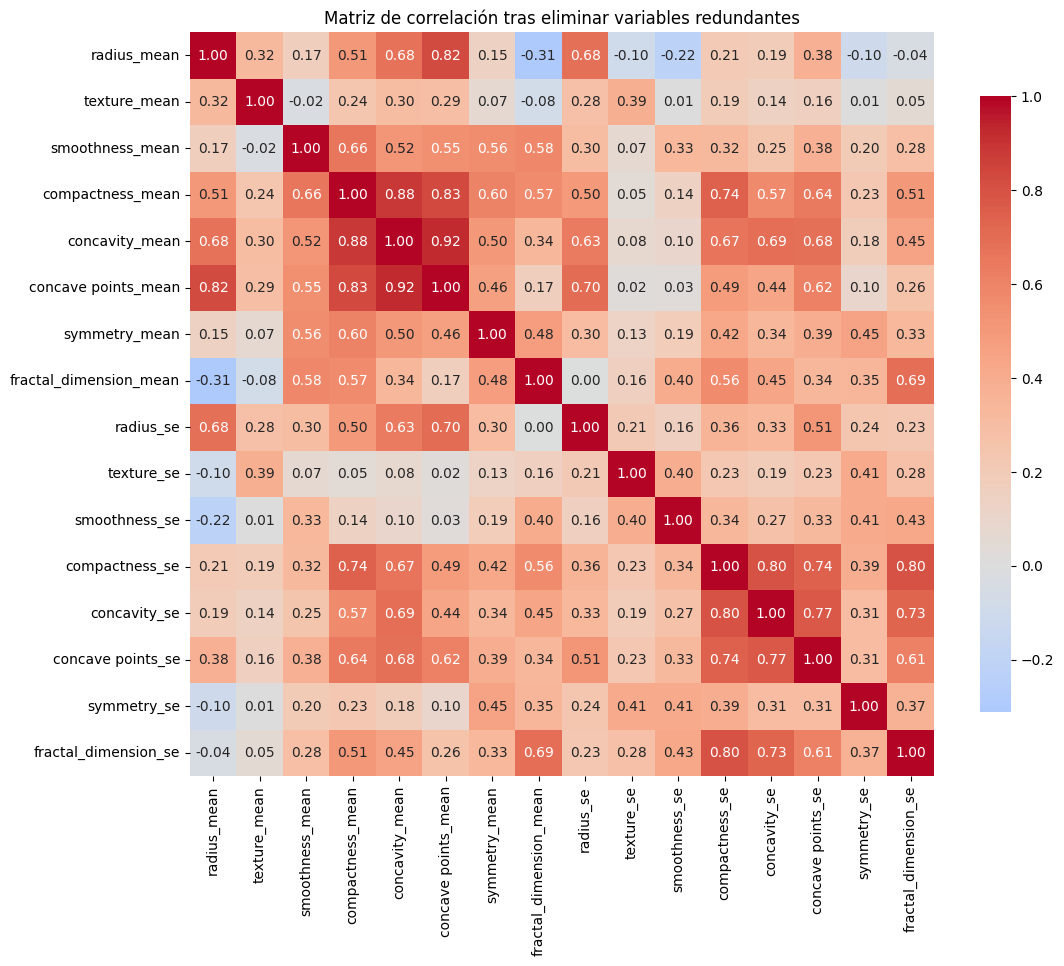


Pares con correlación > 0.9 (conjunto final):
Ninguno


In [4]:
cancer_copy = cancer_df.copy()

def pares_altos(frame, umbral=0.9):
    corr = frame.select_dtypes(include='number').corr().abs()
    mask = np.triu(np.ones(corr.shape), k=1).astype(bool)
    pares = corr.where(mask).stack()
    return pares[pares > umbral].sort_values(ascending=False)

print("Pares con correlación > 0.9 (conjunto completo):")
print(pares_altos(cancer_copy).round(3).to_string())

worst_cols = [c for c in cancer_copy.columns if c.endswith('_worst')]
cancer_copy = cancer_copy.drop(columns=worst_cols)
print("\nPares con correlación > 0.9 (sin columnas _worst):")
print(pares_altos(cancer_copy).round(3).to_string())

cancer_copy = cancer_copy.drop(columns=['perimeter_mean', 'perimeter_se', 'area_mean', 'area_se'])
print("\nPares con correlación > 0.9 (conservando radius):")
print(pares_altos(cancer_copy).round(3).to_string())

plt.figure(figsize=(12, 10))
sns.heatmap(cancer_copy.select_dtypes(include='number').corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, square=True, cbar_kws={'shrink': 0.8})
plt.title('Matriz de correlación tras eliminar variables redundantes')
plt.show()

cancer_copy = cancer_copy.drop(columns=['concavity_mean'])
restantes = pares_altos(cancer_copy)
print("\nPares con correlación > 0.9 (conjunto final):")
print("Ninguno" if restantes.empty else restantes.round(3).to_string())

**De `radius`, `perimeter` y `area`, ¿cuál mantendrías y por qué?**

Se conserva **`radius`**. Es la medida lineal más fundamental: el perímetro (≈ 2πr) y el área (≈ πr²) son funciones directas del radio, por lo que las tres comparten esencialmente la misma información de tamaño. Mantener `radius` preserva esa señal con la variable más simple e interpretable, y se eliminan `perimeter` y `area` (en sus versiones `_mean` y `_se`).

**Si eliminas alguna otra variable, justifica tu elección.**

Tras la depuración persiste una correlación alta (**0.92**) entre `concavity_mean` y `concave points_mean`. Se conserva **`concave points_mean`** por su mayor asociación con la variable objetivo (correlación de 0.78 frente a 0.70 de `concavity_mean`) y se elimina `concavity_mean`. Con esto ningún par supera el umbral de 0.9. En total se descartan **15 columnas**, que serán precisamente las que elimine el transformador `preprocessing`.

## 4. Preparación de datos y función de evaluación

Se separan los predictores de la variable objetivo a partir del dataframe original (la eliminación de variables correlacionadas se integra después en el pipeline), se codifica `diagnosis` como 0 (benigno) y 1 (maligno) y se divide en entrenamiento y prueba (80:20, `random_state=1`). La función `evaluate_model` calcula recall, precisión y exactitud.

In [5]:
X = cancer_df.drop(columns='diagnosis')
y = cancer_df['diagnosis'].map({'B': 0, 'M': 1})   # Benigno = 0, Maligno = 1

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

def evaluate_model(y_real, y_pred):
    recall = recall_score(y_real, y_pred)
    precision = precision_score(y_real, y_pred)
    accuracy = accuracy_score(y_real, y_pred)
    print(f"Recall   : {recall:.4f}")
    print(f"Precisión: {precision:.4f}")
    print(f"Exactitud: {accuracy:.4f}")
    return {'Recall': recall, 'Precision': precision, 'Accuracy': accuracy}

Entrenamiento: (455, 30) | Prueba: (114, 30)


## 5. Modelo 1: eliminación de variables correlacionadas (`Correlation_Clean`)

Un `ColumnTransformer` descarta las columnas identificadas en la sección 3 y conserva el resto; el pipeline lo combina con una regresión logística.

In [6]:
columnas_correlacionadas = (
    ['radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst',
     'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst',
     'fractal_dimension_worst']
    + ['perimeter_mean', 'perimeter_se', 'area_mean', 'area_se']
    + ['concavity_mean']
)

preprocessing = ColumnTransformer(
    transformers=[('drop_correlated', 'drop', columnas_correlacionadas)],
    remainder='passthrough')

modelo_corr = make_pipeline(preprocessing, LogisticRegression(max_iter=10000))
modelo_corr.fit(X_train, y_train)

metricas_corr = evaluate_model(y_test, modelo_corr.predict(X_test))

resultados = pd.DataFrame([{'Modelo': 'Correlation_Clean', **metricas_corr}])
resultados

Recall   : 0.7619
Precisión: 0.8889
Exactitud: 0.8772


,Modelo,Recall,Precision,Accuracy
0,Correlation_Clean,0.761905,0.888889,0.877193


## 6. Modelo 2: escalado estándar y PCA (`Standard_PCA`)

Como alternativa para reducir la multicolinealidad, el pipeline aplica escalado estándar, PCA con el número mínimo de componentes que explican al menos el 90 % de la varianza, y regresión logística.

In [7]:
modelo_pca = make_pipeline(
    StandardScaler(),
    PCA(n_components=0.90),
    LogisticRegression(max_iter=10000))
modelo_pca.fit(X_train, y_train)

metricas_pca = evaluate_model(y_test, modelo_pca.predict(X_test))

n_componentes = modelo_pca.named_steps['pca'].n_components_
var_explicada = modelo_pca.named_steps['pca'].explained_variance_ratio_.sum()
print(f"\nComponentes principales empleados: {n_componentes} "
      f"(varianza explicada: {var_explicada:.2%})")

resultados = pd.concat(
    [resultados, pd.DataFrame([{'Modelo': 'Standard_PCA', **metricas_pca}])],
    ignore_index=True)
resultados

Recall   : 0.9286
Precisión: 1.0000
Exactitud: 0.9737

Componentes principales empleados: 7 (varianza explicada: 91.08%)


,Modelo,Recall,Precision,Accuracy
0,Correlation_Clean,0.761905,0.888889,0.877193
1,Standard_PCA,0.928571,1.000000,0.973684


> Se emplearon **7 componentes principales**, el mínimo necesario para explicar al menos el 90 % de la varianza (en conjunto acumulan **91.08 %**).

## 7. Modelo 3: transformación Yeo-Johnson (`Correlation_Yeo`)

Dado que las variables presentan sesgo, se añade una transformación Yeo-Johnson al pipeline del modelo 1 para normalizar sus distribuciones antes de la regresión logística.

In [8]:
modelo_yeo = make_pipeline(
    preprocessing,
    PowerTransformer(method='yeo-johnson'),
    LogisticRegression(max_iter=10000))
modelo_yeo.fit(X_train, y_train)

metricas_yeo = evaluate_model(y_test, modelo_yeo.predict(X_test))

resultados = pd.concat(
    [resultados, pd.DataFrame([{'Modelo': 'Correlation_Yeo', **metricas_yeo}])],
    ignore_index=True)
resultados

Recall   : 0.9524
Precisión: 1.0000
Exactitud: 0.9825


,Modelo,Recall,Precision,Accuracy
0,Correlation_Clean,0.761905,0.888889,0.877193
1,Standard_PCA,0.928571,1.000000,0.973684
2,Correlation_Yeo,0.952381,1.000000,0.982456


## 8. Variables más influyentes

Se recuperan los predictores que usa el modelo `Correlation_Yeo` y se grafican los 10 coeficientes de mayor magnitud, respetando su signo.

Número de predictores: 15


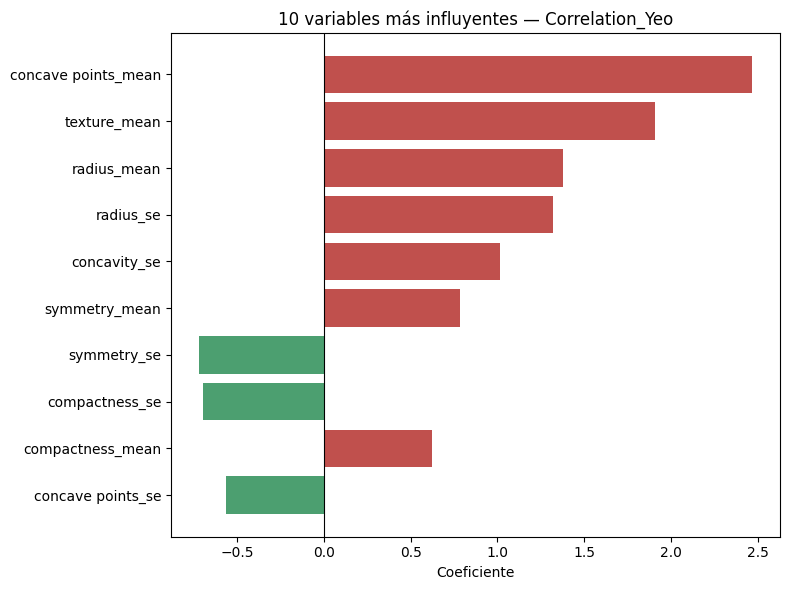

In [9]:
nombres = modelo_yeo.named_steps['columntransformer'].get_feature_names_out()
nombres = [n.replace('remainder__', '') for n in nombres]
print("Número de predictores:", len(nombres))

coeficientes = modelo_yeo.named_steps['logisticregression'].coef_[0]
coef_series = pd.Series(coeficientes, index=nombres)

top10 = coef_series.reindex(coef_series.abs().sort_values(ascending=False).index).head(10)

vals = top10.values[::-1]
idx = top10.index[::-1]
colores = ['#C0504D' if v > 0 else '#4C9F70' for v in vals]

plt.figure(figsize=(8, 6))
plt.barh(idx, vals, color=colores)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Coeficiente')
plt.title('10 variables más influyentes — Correlation_Yeo')
plt.tight_layout()
plt.show()

> El modelo utiliza **15 predictores** (las variables que sobreviven al transformador `preprocessing`).
>
> Los coeficientes **positivos** (rojo) empujan la predicción hacia *Maligno* y los **negativos** (verde) hacia *Benigno*. Las variables más influyentes son `concave points_mean`, `texture_mean` y `radius_mean`, todas positivas: a mayor número de puntos cóncavos, textura y radio, mayor probabilidad de malignidad, lo cual es coherente con el comportamiento clínico esperado de un tumor maligno.

## 9. Comparativa de modelos, matriz de confusión y curva ROC

Se comparan los tres modelos y se evalúa el mejor con su matriz de confusión y su curva ROC.

,Modelo,Recall,Precision,Accuracy
0,Correlation_Clean,0.761905,0.888889,0.877193
1,Standard_PCA,0.928571,1.000000,0.973684
2,Correlation_Yeo,0.952381,1.000000,0.982456


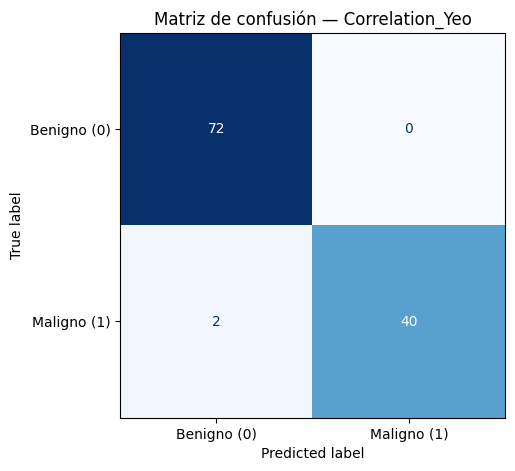

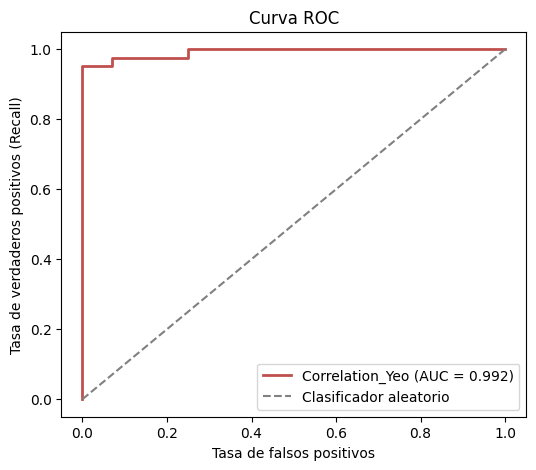

In [10]:
display(resultados)

mejor_modelo = modelo_yeo
y_pred_mejor = mejor_modelo.predict(X_test)
y_proba_mejor = mejor_modelo.predict_proba(X_test)[:, 1]

fig, ax = plt.subplots(figsize=(5.5, 5))
cm = confusion_matrix(y_test, y_pred_mejor)
ConfusionMatrixDisplay(cm, display_labels=['Benigno (0)', 'Maligno (1)']).plot(
    ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Matriz de confusión — Correlation_Yeo')
plt.show()

fpr, tpr, _ = roc_curve(y_test, y_proba_mejor)
auc = roc_auc_score(y_test, y_proba_mejor)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='#C0504D', lw=2, label=f'Correlation_Yeo (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Clasificador aleatorio')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos (Recall)')
plt.title('Curva ROC')
plt.legend(loc='lower right')
plt.show()

**¿Qué significa cada valor de la matriz de confusión?**

Para el mejor modelo (**Correlation_Yeo**), sobre las 114 muestras de prueba:

- **Verdaderos negativos (72):** tumores benignos correctamente clasificados como benignos.
- **Falsos positivos (0):** benignos clasificados erróneamente como malignos.
- **Falsos negativos (2):** malignos clasificados erróneamente como benignos (el error más delicado en un contexto clínico).
- **Verdaderos positivos (40):** malignos correctamente clasificados como malignos.

**¿Qué indica la curva ROC?**

La curva se eleva con rapidez hacia la esquina superior izquierda, con un **AUC = 0.992**, muy cercano a 1. Esto significa que el modelo distingue casi perfectamente entre clases: para casi cualquier umbral consigue una alta tasa de verdaderos positivos con muy pocos falsos positivos.

## 10. Probabilidades predichas y umbral de decisión

Se grafica la distribución de las probabilidades predichas de la clase maligna, separando por clase real, para analizar el umbral de decisión.

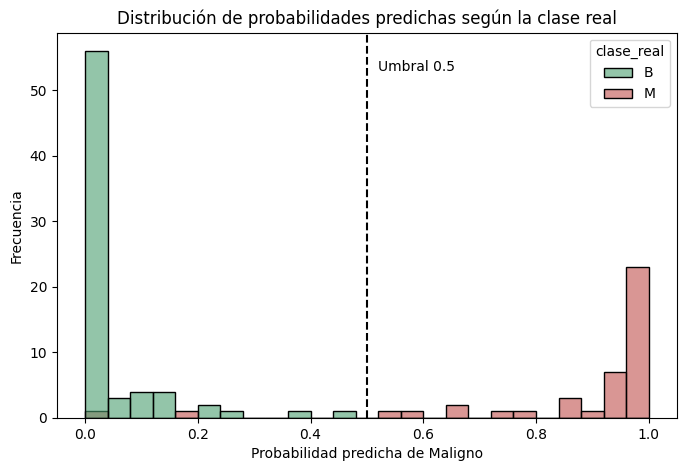

In [11]:
prob_df = pd.DataFrame({
    'probabilidad': y_proba_mejor,
    'clase_real': y_test.map({0: 'B', 1: 'M'}).values})

plt.figure(figsize=(8, 5))
ax = sns.histplot(data=prob_df, x='probabilidad', hue='clase_real', bins=25,
                  multiple='layer', palette={'B': '#4C9F70', 'M': '#C0504D'}, alpha=0.6)
ax.axvline(0.5, color='black', linestyle='--')
ax.text(0.52, ax.get_ylim()[1] * 0.9, 'Umbral 0.5')
ax.set_xlabel('Probabilidad predicha de Maligno')
ax.set_ylabel('Frecuencia')
ax.set_title('Distribución de probabilidades predichas según la clase real')
plt.show()

**¿Cuál es el umbral por defecto de scikit-learn?**

El umbral por defecto es **0.5**: si la probabilidad predicha de la clase positiva (Maligno) es ≥ 0.5 se clasifica como maligno; en caso contrario, como benigno.

**En un modelo de diagnóstico médico, ¿cuál es la métrica más importante?**

El **recall (sensibilidad)** de la clase maligna. Un **falso negativo** —diagnosticar como benigno un tumor que en realidad es maligno— puede retrasar el tratamiento y tener consecuencias graves, mucho más costosas que un falso positivo, que normalmente solo deriva en estudios adicionales.

**¿Cómo cambiarías el umbral y por qué?**

Lo **disminuiría** por debajo de 0.5. Bajar el umbral hace que el modelo clasifique como malignos los casos con menor probabilidad, lo que **aumenta el recall** y reduce los falsos negativos, a costa de aceptar algunos falsos positivos más. En un tamizaje de cáncer ese intercambio es deseable: es preferible una alarma de más que pasar por alto un tumor maligno.

---

**Declaración de uso de IA**

Para el desarrollo de este proyecto se utilizó la siguiente herramienta de inteligencia artificial:

Google. (2026). Gemini (basado en Gemini 3.1) [Modelo de lenguaje grande], utilizado para optimización y depuración de código. https://gemini.google.com

---